# Model Training

Train and compare regression models to predict daily product sales.

I use a time-based Train/Test Split to evaluate how well my models predict future sales.

In [1]:
import pandas as pd

# Load prepared dataset
df = pd.read_csv("ml_ready_bakery.csv", parse_dates=["date"])

# Sort chronologically
df = df.sort_values(["date", "article"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())

df.head()

Dataset shape: (13467, 7)
Date range: 2021-01-03 00:00:00 to 2022-09-30 00:00:00


,date,article,daily_quantity_sold,day_of_week,month,previous_sales,avg_last_3_sales
0,2021-01-03,BAGUETTE,36.0,6,1,46.0,46.0
1,2021-01-03,BANETTE,35.0,6,1,40.0,40.0
2,2021-01-03,BOULE 400G,11.0,6,1,11.0,11.0
3,2021-01-03,BRIOCHE,3.0,6,1,2.0,2.0
4,2021-01-03,CAMPAGNE,9.0,6,1,10.0,10.0


## Time-Based Train/Test Split

Split the dataset chronologically: 80% of dates for training and 20% for testing.

This ensures that the model is trained on historical data and evaluated on future observations.

In [2]:
# Time-based 80/20 split
dates = df["date"].drop_duplicates()
split_date = dates.iloc[int(len(dates) * 0.8)]

train_df = df[df["date"] < split_date].copy()
test_df = df[df["date"] >= split_date].copy()

# Separate Features and Target
X_train = train_df.drop(columns=["daily_quantity_sold", "date"])
X_test = test_df.drop(columns=["daily_quantity_sold", "date"])

y_train = train_df["daily_quantity_sold"]
y_test = test_df["daily_quantity_sold"]

In [3]:
from sklearn.preprocessing import OneHotEncoder

# One-Hot Encoding
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

train_encoded = pd.DataFrame(
    encoder.fit_transform(X_train[["article"]]),
    columns=encoder.get_feature_names_out(["article"]),
    index=X_train.index
)

test_encoded = pd.DataFrame(
    encoder.transform(X_test[["article"]]),
    columns=encoder.get_feature_names_out(["article"]),
    index=X_test.index
)

# Replace article with encoded columns
X_train = pd.concat([X_train.drop(columns=["article"]), train_encoded], axis=1)
X_test = pd.concat([X_test.drop(columns=["article"]), test_encoded], axis=1)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train.head()

X_train: (10723, 30)
X_test: (2744, 30)


,day_of_week,month,previous_sales,avg_last_3_sales,article_BAGUETTE,article_BANETTE,article_BOULE 400G,article_BRIOCHE,article_CAMPAGNE,article_CEREAL BAGUETTE,...,article_PAIN AU CHOCOLAT,article_PAIN AUX RAISINS,article_PAIN BANETTE,article_SAND JB EMMENTAL,article_SANDWICH COMPLET,article_SPECIAL BREAD,article_TARTELETTE,article_TRADITIONAL BAGUETTE,article_TRAITEUR,article_VIK BREAD
0,6,1,46.0,46.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,6,1,40.0,40.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,6,1,11.0,11.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,6,1,2.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,6,1,10.0,10.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Baseline Model

Use previous recorded sales as a simple prediction of product demand.

This provides a benchmark to evaluate whether our ML models actually improve forecasting accuracy.

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline prediction
baseline_pred = X_test["previous_sales"]

# Evaluate baseline
mae = mean_absolute_error(y_test, baseline_pred)
rmse = mean_squared_error(y_test, baseline_pred) ** 0.5
r2 = r2_score(y_test, baseline_pred)

print("Baseline MAE:", round(mae, 2))
print("Baseline RMSE:", round(rmse, 2))
print("Baseline R²:", round(r2, 2))

Baseline MAE: 8.8
Baseline RMSE: 21.86
Baseline R²: 0.88


## Train and Compare Regression Models

Train different regression models using the same training data and evaluate their performance against the baseline.

#### Linear Regression

In [5]:
from sklearn.linear_model import LinearRegression

# Train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Make predictions
lr_pred = lr_model.predict(X_test)

# Evaluate model
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = mean_squared_error(y_test, lr_pred) ** 0.5
lr_r2 = r2_score(y_test, lr_pred)

print("Linear Regression MAE:", round(lr_mae, 2))
print("Linear Regression RMSE:", round(lr_rmse, 2))
print("Linear Regression R²:", round(lr_r2, 2))

Linear Regression MAE: 9.0
Linear Regression RMSE: 20.3
Linear Regression R²: 0.9


#### Decision Tree Regressor

In [6]:
from sklearn.tree import DecisionTreeRegressor

# Train Decision Tree
dt_model = DecisionTreeRegressor(random_state=8)
dt_model.fit(X_train, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test)

# Evaluate model
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_rmse = mean_squared_error(y_test, dt_pred) ** 0.5
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree MAE:", round(dt_mae, 2))
print("Decision Tree RMSE:", round(dt_rmse, 2))
print("Decision Tree R²:", round(dt_r2, 2))

Decision Tree MAE: 7.74
Decision Tree RMSE: 18.25
Decision Tree R²: 0.92


#### KNN (scaling for it)

In [7]:
from sklearn.preprocessing import StandardScaler

# Scale numerical features for KNN
numeric_cols = ["day_of_week", "month", "previous_sales", "avg_last_3_sales"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [8]:
from sklearn.neighbors import KNeighborsRegressor

# Train KNN
knn_model = KNeighborsRegressor(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# Make predictions
knn_pred = knn_model.predict(X_test_scaled)

# Evaluate model
knn_mae = mean_absolute_error(y_test, knn_pred)
knn_rmse = mean_squared_error(y_test, knn_pred) ** 0.5
knn_r2 = r2_score(y_test, knn_pred)

print("KNN MAE:", round(knn_mae, 2))
print("KNN RMSE:", round(knn_rmse, 2))
print("KNN R²:", round(knn_r2, 2))

KNN MAE: 6.35
KNN RMSE: 16.48
KNN R²: 0.93


#### Random Forest Regressor

In [9]:
from sklearn.ensemble import RandomForestRegressor

# Train Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=8)
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Evaluate model
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = mean_squared_error(y_test, rf_pred) ** 0.5
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))
print("Random Forest R²:", round(rf_r2, 2))

Random Forest MAE: 5.92
Random Forest RMSE: 14.44
Random Forest R²: 0.95


#### Bagging Regressor

In [10]:
from sklearn.ensemble import BaggingRegressor

# Train Bagging
bag_model = BaggingRegressor(n_estimators=100, random_state=8)
bag_model.fit(X_train, y_train)

# Make predictions
bag_pred = bag_model.predict(X_test)

# Evaluate model
bag_mae = mean_absolute_error(y_test, bag_pred)
bag_rmse = mean_squared_error(y_test, bag_pred) ** 0.5
bag_r2 = r2_score(y_test, bag_pred)

print("Bagging MAE:", round(bag_mae, 2))
print("Bagging RMSE:", round(bag_rmse, 2))
print("Bagging R²:", round(bag_r2, 2))

Bagging MAE: 5.92
Bagging RMSE: 14.39
Bagging R²: 0.95


#### Gradient Boosting Regressor

In [11]:
from sklearn.ensemble import GradientBoostingRegressor

# Train Gradient Boosting
gb_model = GradientBoostingRegressor(n_estimators=100, random_state=8)
gb_model.fit(X_train, y_train)

# Make predictions
gb_pred = gb_model.predict(X_test)

# Evaluate model
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = mean_squared_error(y_test, gb_pred) ** 0.5
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting MAE:", round(gb_mae, 2))
print("Gradient Boosting RMSE:", round(gb_rmse, 2))
print("Gradient Boosting R²:", round(gb_r2, 2))

Gradient Boosting MAE: 6.09
Gradient Boosting RMSE: 14.6
Gradient Boosting R²: 0.95


#### AdaBoost Regressor

In [12]:
from sklearn.ensemble import AdaBoostRegressor

# Train AdaBoost
ada_model = AdaBoostRegressor(n_estimators=100, random_state=8)
ada_model.fit(X_train, y_train)

# Make predictions
ada_pred = ada_model.predict(X_test)

# Evaluate model
ada_mae = mean_absolute_error(y_test, ada_pred)
ada_rmse = mean_squared_error(y_test, ada_pred) ** 0.5
ada_r2 = r2_score(y_test, ada_pred)

print("AdaBoost MAE:", round(ada_mae, 2))
print("AdaBoost RMSE:", round(ada_rmse, 2))
print("AdaBoost R²:", round(ada_r2, 2))

AdaBoost MAE: 8.07
AdaBoost RMSE: 19.25
AdaBoost R²: 0.91


## Model Comparison

Compare all models using MAE, RMSE, and R².

MAE is our primary evaluation metric, as it measures the average prediction error in units sold.

In [13]:
# Compare model performance
results = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression", "Decision Tree", "KNN",
              "Random Forest", "Bagging", "Gradient Boosting", "AdaBoost"],
    "MAE": [mae, lr_mae, dt_mae, knn_mae, rf_mae, bag_mae, gb_mae, ada_mae],
    "RMSE": [rmse, lr_rmse, dt_rmse, knn_rmse, rf_rmse, bag_rmse, gb_rmse, ada_rmse],
    "R²": [r2, lr_r2, dt_r2, knn_r2, rf_r2, bag_r2, gb_r2, ada_r2]
})

results = results.sort_values("MAE").reset_index(drop=True)

results.round(2)

,Model,MAE,RMSE,R²
0,Random Forest,5.92,14.44,0.95
1,Bagging,5.92,14.39,0.95
2,Gradient Boosting,6.09,14.60,0.95
3,KNN,6.35,16.48,0.93
4,Decision Tree,7.74,18.25,0.92
5,AdaBoost,8.07,19.25,0.91
6,Baseline,8.80,21.86,0.88
7,Linear Regression,9.00,20.30,0.90


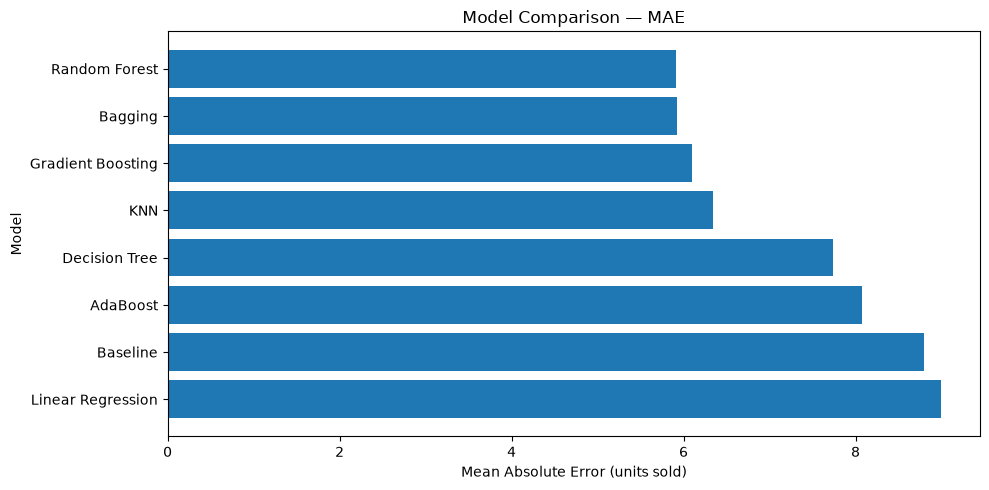

,Model,MAE,RMSE,R²
0,Random Forest,5.92,14.44,0.95
1,Bagging,5.92,14.39,0.95
2,Gradient Boosting,6.09,14.60,0.95
3,KNN,6.35,16.48,0.93
4,Decision Tree,7.74,18.25,0.92
5,AdaBoost,8.07,19.25,0.91
6,Baseline,8.80,21.86,0.88
7,Linear Regression,9.00,20.30,0.90


In [14]:
import matplotlib.pyplot as plt

# Visualize model comparison
plt.figure(figsize=(10, 5))

plt.barh(results["Model"], results["MAE"])
plt.gca().invert_yaxis()

plt.title("Model Comparison — MAE")
plt.xlabel("Mean Absolute Error (units sold)")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

display(results.round(2))


### Initial Results

**Random Forest** and **Bagging** achieved the best performance, with MAE of approximately 5.92 and R² of 0.95.

Both models reduced prediction error by approximately 33% compared to the baseline (MAE = 8.80).


## Hyperparameter Tuning

Optimize Random Forest and Bagging using GridSearchCV with a chronological validation split.

#### Split train into train/validation (80/20)

In [23]:
import numpy as np
from sklearn.model_selection import GridSearchCV

# Split training dates into Train and Validation
dates = train_df["date"].drop_duplicates().sort_values()
val_start = dates.iloc[int(len(dates) * 0.8)]

train_idx = np.where(train_df["date"] < val_start)[0]
val_idx = np.where(train_df["date"] >= val_start)[0]

cv_split = [(train_idx, val_idx)]

print("Training rows:", len(train_idx))
print("Validation rows:", len(val_idx))
print("Validation starts:", val_start)

Training rows: 8586
Validation rows: 2137
Validation starts: 2022-02-24 00:00:00


#### Random Forest Hyperparameter Tuning

In [33]:
rf_params = {
    "n_estimators": [100, 350, 370],
    "max_depth": [10, 12, 14]
}

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=8),
    param_grid=rf_params,
    cv=cv_split,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best parameters:", rf_grid.best_params_)
print("Validation MAE:", round(-rf_grid.best_score_, 2))

Best parameters: {'max_depth': 12, 'n_estimators': 350}
Validation MAE: 5.02


#### Bagging Hyperparameter Tuning

In [34]:
bag_params = {
    "n_estimators": [100, 200, 350],
    "max_samples": [0.7, 0.8, 1.0]
}

bag_grid = GridSearchCV(
    BaggingRegressor(random_state=8),
    param_grid=bag_params,
    cv=cv_split,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

bag_grid.fit(X_train, y_train)

print("Best parameters:", bag_grid.best_params_)
print("Validation MAE:", round(-bag_grid.best_score_, 2))

Best parameters: {'max_samples': 0.7, 'n_estimators': 200}
Validation MAE: 5.01


### Tuning Results

Both models achieved nearly identical results after hyperparameter tuning.

Bagging achieved the lowest Validation MAE (5.01), slightly outperforming Random Forest (5.02).

**Selected Model: Bagging**, with 200 estimators and max_samples = 0.7.

Next, we evaluate the tuned model on the Test dataset.

## Final Model Evaluation

Evaluate the selected Bagging model on the Test dataset using MAE, RMSE, and R².

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select the tuned Bagging model
best_model = bag_grid.best_estimator_

# Predict on Test data
y_pred = best_model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print("Final Model: Bagging")
print("Test MAE:", round(mae, 2))
print("Test RMSE:", round(rmse, 2))
print("Test R²:", round(r2, 2))

Final Model: Bagging
Test MAE: 5.86
Test RMSE: 14.79
Test R²: 0.95



### Final Evaluation Results

The tuned Bagging model achieved a Test MAE of 5.86, compared to 5.92 before tuning.

RMSE increased slightly from 14.39 to 14.79, while R² remained at 0.95.

**Conclusion:** Hyperparameter tuning slightly improved average prediction accuracy, but the overall performance remained similar.

**Limitation:** The Test dataset was previously used for model comparison, so these results are not fully independent.


## Business Insights & Recommendations

**Business Value**

The final Bagging model achieved a Test MAE of 5.86 units, reducing prediction error by approximately 33% compared to the baseline (MAE = 8.80).

**Business Implications**

- **Production Planning:** More accurate daily sales forecasts can support better production decisions for individual bakery products.
- **Waste Reduction:** Improved demand estimates may help reduce overproduction and unsold products.
- **Product Availability:** Forecasts can help identify expected demand and reduce the risk of underproduction.

**Limitations**

- Prediction errors may be higher during unusual demand fluctuations.
- Historical sales features require previous recorded sales to be available.
- The Test dataset was already used during model comparison, so the final evaluation is not fully independent.

**Final Recommendation**

The model shows promising potential as a decision-support tool for daily bakery production planning. Further validation on new sales data is recommended before operational deployment.